# Rain Prediction — Deployment / finalization (K=5 model)

Freezes the winner from EXP-007: **base + temporal + spatial(K=5)**, frozen EXP-002
hyperparameters. This notebook:

1. rebuilds the 44-feature matrix **depuis les sorties du pipeline** — features de base et split
   depuis `weatherAUS_{X,y}_{train,test}.csv`, features retardées/voisines depuis
   `weatherAUS_trend_grouped.csv` (pré-imputation),
2. fits **isotonic calibration** on a leakage-free chronological hold-out tail and freezes the
   **PR-crossover threshold** on the *calibrated* scale,
3. **refits the XGBoost on the full training period** (2007→2015) for the shipped predictor,
4. evaluates once on the 2016+ test set,
5. saves the intermediate models **et** a single self-contained **`joblib` artifact** (model +
   isotonic map + threshold + feature order + neighbour graph + metadata) dans `../../models/`,
   puis démontre le chemin d'inférence.

> **Calibration note.** On time-ordered data you cannot both train a single model on 100% of the
> period *and* calibrate it leakage-free (cross-val calibration needs every row held out once, which
> `TimeSeriesSplit` does not provide). The principled compromise used here: fit the isotonic map on a
> model trained on the chronological **first 85%** and validated on the held-out **last 15%**, then
> apply that monotone map to the **full-train** model. Both models share the regularized config, so
> their probability distributions match closely; the test-set ECE below confirms calibration holds.

Outputs -> `DEPLOY_result.txt`, artefacts dans `../../models/`.


## 1. Setup

In [1]:
# --- Environnement ---
# Ce notebook tourne en local sur les sorties du pipeline de preprocessing
# (dossier ../../data). Sur Colab, installer les dépendances puis pointer
# WEATHER_DATA_DIR vers le dossier contenant les CSV du pipeline.
import subprocess, sys as _sys
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run([_sys.executable, '-m', 'pip', '-q', 'install', '-U', 'xgboost', 'joblib'],
                   check=False)
    subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total,driver_version',
                    '--format=csv,noheader'], check=False)

print(f'Running on Colab: {IN_COLAB}')


Running on Colab: True


In [2]:
import os, sys, json, zipfile, warnings
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import TimeSeriesSplit
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score, roc_auc_score,
    precision_recall_curve, auc, brier_score_loss, log_loss)
from sklearn.calibration import calibration_curve
import xgboost as xgb
from xgboost import XGBClassifier
warnings.filterwarnings('ignore', category=UserWarning, module='xgboost')

RANDOM_STATE = 42
TEST_CUTOFF = pd.Timestamp('2016-01-01')
K_NEIGHBOURS = 5

def _gpu_available():
    try:
        d = xgb.DMatrix(np.zeros((8, 2)), label=np.zeros(8))
        xgb.train({'device': 'cuda', 'tree_method': 'hist'}, d, num_boost_round=1)
        return True
    except Exception as e:
        print(f'CUDA probe failed ({type(e).__name__}); CPU.'); return False

USE_GPU = _gpu_available()
DEVICE = 'cuda' if USE_GPU else 'cpu'
XGB_KW = dict(tree_method='hist', device=DEVICE, eval_metric='logloss',
              random_state=RANDOM_STATE, n_jobs=-1)
def make_xgb(**ov):
    p = dict(XGB_KW); p.update(ov); return XGBClassifier(**p)

# Frozen EXP-002 config (the EXP-007 winner used these).
V2_PARAMS = dict(max_depth=6, min_child_weight=10, gamma=2.0, reg_lambda=20, reg_alpha=0.5,
                 learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, n_estimators=800)
print(f'xgboost {xgb.__version__} | device {DEVICE}')

xgboost 3.4.0 | device cuda


### Output setup

In [3]:
os.makedirs('figures', exist_ok=True)
_PATH = 'DEPLOY_result.txt'
_FILE = open(_PATH, 'w', encoding='utf-8')
class _Tee:
    def __init__(self, *s): self._s = s
    def write(self, d):
        for s in self._s: s.write(d)
    def flush(self):
        for s in self._s: s.flush()
    def isatty(self): return False
_ORIG = sys.stdout; sys.stdout = _Tee(_ORIG, _FILE)
print('# Deployment finalization (K=5) — numerical outputs')
print(f'# Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')
def log_section(t):
    print('\n' + '=' * 72 + '\n' + t + '\n' + '=' * 72)
def save_fig(name, fig=None):
    fig = fig or plt.gcf(); p = f'figures/{name}.png'
    fig.savefig(p, dpi=150, bbox_inches='tight'); print(f'  [saved {p}]')
def ece(y, p, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1); idx = np.digitize(p, edges[1:-1]); e = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.sum(): e += (m.sum()/len(y)) * abs(y[m].mean() - p[m].mean())
    return e

# --- Sérialisation des modèles ---------------------------------------------
# Chaque étape du notebook est enregistrée dans <repo>/models sous forme d'un
# dict joblib : le modèle + les métadonnées nécessaires pour le rejouer.
MODEL_DIR = os.environ.get('WEATHER_MODEL_DIR', '../../models')
os.makedirs(MODEL_DIR, exist_ok=True)
NOTEBOOK = 'EXP-007_XGBoost_deploy'

def save_model(obj, name, **meta):
    """Sauvegarde `obj` dans MODEL_DIR/<name>.joblib avec ses métadonnées."""
    path = f'{MODEL_DIR}/{name}.joblib'
    joblib.dump({'model': obj,
                 'notebook': NOTEBOOK,
                 'created_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
                 **meta}, path)
    print(f'  [saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)]')


# Deployment finalization (K=5) — numerical outputs
# Generated: 2026-08-11 13:00:13

2. Data + features (sorties du pipeline)
X_train (113506, 29) | X_test (25314, 29)
Train 2007-11-01 -> 2015-12-31 | Test 2016-01-01 -> 2017-06-25
Stations : 49 | pluie train 21.9574% / test 22.6950%
Pré-imputation : 138,820 lignes x 27 colonnes (292,371 NaN conservés)
BASE features: 25 | X_all (138820, 25)
Temporal features: 12 -> ['Humidity3pm_lag1', 'Pressure3pm_lag1', 'Rainfall_lag1', 'Cloud3pm_lag1', 'Sunshine_lag1', 'Temp3pm_lag1', 'WindGustSpeed_lag1', 'Pressure_3d_chg', 'Humidity_3d_mean', 'Rainfall_3d_sum', 'RainToday_lag1', 'days_since_rain']
Mean NaN share across temporal features: 9.8% (left for XGBoost native handling)
<xml><var name="_dummy_ipython_val"  />
<var name="_dummy_special_var"  />
<var name="BASE_FEATURES" type="list" qualifier="builtins" value="%5B%27MinTemp%27%2C %27MaxTemp%27%2C %27Rainfall%27%2C %27Evaporation%27%2C %27Sunshine%27%2C %27WindGustSpeed%27%2C %27WindSpeed9am%2

## 2. Chargement pipeline + features (base + temporal + spatial K=5)

In [4]:
log_section('2. Data + features (sorties du pipeline)')

# Sorties du pipeline, dans <repo>/data :
#   3.preprocessing_trend_group.ipynb -> weatherAUS_trend_grouped.csv
#   4_preprocessing_imputation.ipynb  -> weatherAUS_MICE_cyclic.csv
#                                        weatherAUS_X_train.csv / weatherAUS_y_train.csv
#                                        weatherAUS_X_test.csv  / weatherAUS_y_test.csv
DATA_DIR = os.environ.get('WEATHER_DATA_DIR', '../../data')

# Matrices déjà splitées, encodées (LabelEncoder) et scalées (RobustScaler ajusté
# sur le train uniquement) par 4_preprocessing_imputation.ipynb.
X_train = pd.read_csv(f'{DATA_DIR}/weatherAUS_X_train.csv')
X_test  = pd.read_csv(f'{DATA_DIR}/weatherAUS_X_test.csv')
y_train = pd.read_csv(f'{DATA_DIR}/weatherAUS_y_train.csv').squeeze('columns').astype(int)
y_test  = pd.read_csv(f'{DATA_DIR}/weatherAUS_y_test.csv').squeeze('columns').astype(int)

# Index (Date, Location) aligné ligne à ligne sur X_train / X_test :
# weatherAUS_MICE_cyclic.csv est trié par Date et le pipeline y applique le même
# seuil TEST_CUTOFF, donc ses len(X_train) premières lignes SONT celles de X_train.
meta = pd.read_csv(f'{DATA_DIR}/weatherAUS_MICE_cyclic.csv',
                   usecols=['Date', 'Location', 'Pressure9am', 'Pressure3pm', 'Temp9am', 'Temp3pm'], parse_dates=['Date'])
meta = meta[['Date', 'Location', 'Pressure9am', 'Pressure3pm', 'Temp9am', 'Temp3pm']]
assert len(meta) == len(X_train) + len(X_test), 'X_train/X_test ne recouvrent pas MICE_cyclic'
meta_train = meta.iloc[:len(X_train)].reset_index(drop=True)
meta_test  = meta.iloc[len(X_train):].reset_index(drop=True)
assert (meta_train['Date'] < TEST_CUTOFF).all(), 'lignes de train postérieures au seuil'
assert (meta_test['Date'] >= TEST_CUTOFF).all(), 'lignes de test antérieures au seuil'

print(f'X_train {X_train.shape} | X_test {X_test.shape}')
print(f'Train {meta_train["Date"].min().date()} -> {meta_train["Date"].max().date()} | '
      f'Test {meta_test["Date"].min().date()} -> {meta_test["Date"].max().date()}')
print(f'Stations : {meta["Location"].nunique()} | pluie train {y_train.mean():.4%} / test {y_test.mean():.4%}')

# Frame AVANT imputation (mêmes lignes, NaN d'origine conservés) : sert à
# reconstruire les features retardées / voisines sans réutiliser de valeur
# reconstruite par MICE.
pre = pd.read_csv(f'{DATA_DIR}/weatherAUS_trend_grouped.csv', parse_dates=['Date'])
assert len(pre) == len(meta), 'weatherAUS_trend_grouped.csv désaligné du pipeline'
print(f'Pré-imputation : {pre.shape[0]:,} lignes x {pre.shape[1]} colonnes '
      f'({pre.isna().sum().sum():,} NaN conservés)')

# --- Features de base (v2) ---
# Features de tendance intra-journalière. Elles sont calculées sur les valeurs
# NON scalées de weatherAUS_MICE_cyclic.csv : une différence de colonnes déjà
# passées au RobustScaler (échelles distinctes) ne serait pas la même grandeur.
for X, m in ((X_train, meta_train), (X_test, meta_test)):
    X['Pressure_diff'] = (m['Pressure3pm'] - m['Pressure9am']).to_numpy()
    X['Temp_diff']     = (m['Temp3pm']     - m['Temp9am']).to_numpy()

# Le pipeline livre 29 colonnes. On retire les mêmes que l'étude LR pour que les
# expériences EXP-001..007 restent comparables entre elles :
DROP_COLS = [
    'WindGustDir', 'WindDir9am', 'WindDir3pm',  # labels encodés ; les sin/cos sont conservés
    'RainToday',                                # quasi-fuite (on donne déjà le reste de la journée)
    'Humidity9am',                              # on garde Humidity3pm (plus prédictive)
    'Month',                                    # redondant avec Date_sin / Date_cos
]
BASE_FEATURES = [c for c in X_train.columns if c not in DROP_COLS]

# Matrice complète dans l'ordre chronologique du pipeline : X_train puis X_test.
# Les blocs de features additionnels (temporel / spatial) viendront s'y coller.
X_all = pd.concat([X_train[BASE_FEATURES], X_test[BASE_FEATURES]], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)
loc_all = meta['Location']
dates   = meta['Date']
N_TRAIN = len(X_train)

def align_to_pipeline(frame, cols):
    """Réaligne un bloc de features indexé par (Date, Location) sur l'ordre des
    lignes du pipeline. Les deux frames partagent la même clé unique, donc le
    réalignement est exact et ne peut pas dupliquer de ligne."""
    key = pd.MultiIndex.from_frame(frame[['Date', 'Location']])
    assert key.is_unique, 'clé (Date, Location) non unique dans le bloc de features'
    out = frame.set_axis(key)[cols].reindex(pd.MultiIndex.from_frame(meta[['Date', 'Location']]))
    return out.reset_index(drop=True)

print(f'BASE features: {len(BASE_FEATURES)} | X_all {X_all.shape}')

# --- Features temporelles (frame pré-imputation) ---
# Toutes les features ci-dessous n'utilisent que les jours <= t-1 (pas d'info du jour
# même, pas de futur), construites par `Location` sur weatherAUS_trend_grouped.csv,
# c'est-à-dire AVANT l'imputation MICE : aucune valeur reconstruite ne peut remonter
# dans un lag. Les NaN qui en résultent (premiers jours / manquants d'origine) sont
# laissés tels quels — XGBoost les gère nativement et EXP-003 a montré que les
# imputer n'apporte rien.
pre_s = pre.sort_values(['Location', 'Date']).copy()
g = pre_s.groupby('Location', sort=False)

LAG_COLS = ['Humidity3pm','Pressure3pm','Rainfall','Cloud3pm','Sunshine','Temp3pm','WindGustSpeed']
feat = pd.DataFrame({'Date': pre_s['Date'].values, 'Location': pre_s['Location'].values})
for c in LAG_COLS:
    feat[f'{c}_lag1'] = g[c].shift(1).values

# multi-day, all strictly past (>= t-1)
feat['Pressure_3d_chg']  = (g['Pressure3pm'].shift(1) - g['Pressure3pm'].shift(4)).values
feat['Humidity_3d_mean'] = g['Humidity3pm'].apply(lambda s: s.shift(1).rolling(3).mean()).values
feat['Rainfall_3d_sum']  = g['Rainfall'].apply(lambda s: s.shift(1).rolling(3).sum()).values

# yesterday's rain flag + days since last rain (computed on the lagged flag -> strictly past)
rt = pre_s['RainToday'].astype(int)          # booléen dans le frame du pipeline
rt_lag = rt.groupby(pre_s['Location'], sort=False).shift(1)
feat['RainToday_lag1'] = rt_lag.values
def _days_since(s):
    out = np.empty(len(s)); cnt = 9999.0
    for i, v in enumerate(s.to_numpy()):
        out[i] = cnt
        cnt = 0.0 if v == 1 else (cnt + 1 if cnt < 9999 else 9999)
    return out
feat['days_since_rain'] = (
    rt_lag.fillna(0).groupby(pre_s['Location'], sort=False).transform(lambda s: _days_since(s)).values)

TEMPORAL_FEATURES = [c for c in feat.columns if c not in ('Date', 'Location')]
X_all[TEMPORAL_FEATURES] = align_to_pipeline(feat, TEMPORAL_FEATURES)
nan_share = X_all[TEMPORAL_FEATURES].isna().mean().mean()
print(f'Temporal features: {len(TEMPORAL_FEATURES)} -> {TEMPORAL_FEATURES}')
print(f'Mean NaN share across temporal features: {nan_share:.1%} (left for XGBoost native handling)')


In [5]:
# --- Features spatiales (K=5), frame pré-imputation --------------------------
COORDS = {
    'Adelaide': (-34.9285, 138.6007), 'Albany': (-35.0269, 117.8837), 'Albury': (-36.0737, 146.9135),
    'AliceSprings': (-23.6980, 133.8807), 'BadgerysCreek': (-33.8829, 150.7609), 'Ballarat': (-37.5622, 143.8503),
    'Bendigo': (-36.7570, 144.2794), 'Brisbane': (-27.4698, 153.0251), 'Cairns': (-16.9186, 145.7781),
    'Canberra': (-35.2809, 149.1300), 'Cobar': (-31.4958, 145.8389), 'CoffsHarbour': (-30.2986, 153.1094),
    'Dartmoor': (-37.9225, 141.2767), 'Darwin': (-12.4634, 130.8456), 'GoldCoast': (-28.0167, 153.4000),
    'Hobart': (-42.8821, 147.3272), 'Katherine': (-14.4652, 132.2635), 'Launceston': (-41.4332, 147.1441),
    'Melbourne': (-37.8136, 144.9631), 'MelbourneAirport': (-37.6690, 144.8410), 'Mildura': (-34.1855, 142.1625),
    'Moree': (-29.4639, 149.8407), 'MountGambier': (-37.8284, 140.7820), 'MountGinini': (-35.5294, 148.7723),
    'Newcastle': (-32.9283, 151.7817), 'Nhil': (-36.3333, 141.6500), 'NorahHead': (-33.2833, 151.5667),
    'NorfolkIsland': (-29.0408, 167.9547), 'Nuriootpa': (-34.4700, 138.9960), 'PearceRAAF': (-31.6676, 116.0292),
    'Penrith': (-33.7507, 150.6877), 'Perth': (-31.9505, 115.8605), 'PerthAirport': (-31.9385, 115.9672),
    'Portland': (-38.3609, 141.6041), 'Richmond': (-33.6000, 150.7667), 'Sale': (-38.1026, 147.0730),
    'SalmonGums': (-32.9815, 121.6438), 'Sydney': (-33.8688, 151.2093), 'SydneyAirport': (-33.9399, 151.1753),
    'Townsville': (-19.2590, 146.8169), 'Tuggeranong': (-35.4244, 149.0888), 'Uluru': (-25.3444, 131.0369),
    'WaggaWagga': (-35.1082, 147.3598), 'Walpole': (-34.9777, 116.7338), 'Watsonia': (-37.7100, 145.0830),
    'Williamtown': (-32.8150, 151.8428), 'Witchcliffe': (-34.0261, 115.1003), 'Wollongong': (-34.4278, 150.8931),
    'Woomera': (-31.1656, 136.8193),
}
assert set(meta['Location'].unique()) <= set(COORDS)
stations = sorted(COORDS)
def haversine(a, b):
    R = 6371.0; p1, p2 = np.radians(a[0]), np.radians(b[0])
    dphi = np.radians(b[0]-a[0]); dl = np.radians(b[1]-a[1])
    h = np.sin(dphi/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2*R*np.arcsin(np.sqrt(h))
NEIGHBOURS, NEAREST_DIST = {}, {}
for s in stations:
    dd = sorted((haversine(COORDS[s], COORDS[t]), t) for t in stations if t != s)
    NEIGHBOURS[s] = [t for _, t in dd[:K_NEIGHBOURS]]; NEAREST_DIST[s] = dd[0][0]

pre2 = pre.assign(_RainToday=pre['RainToday'].astype(int))
full_dates = pd.date_range(pre['Date'].min(), pre['Date'].max(), freq='D')
WIDE = {v: (pre2.pivot_table(index='Date', columns='Location', values=v, dropna=False)
           .reindex(index=full_dates, columns=stations))
        for v in ['Rainfall','Pressure3pm','Humidity3pm','_RainToday']}
SPEC = [('Rainfall',False),('Rainfall',True),('Pressure3pm',False),('Pressure3pm',True),
        ('Humidity3pm',False),('_RainToday',False)]
sfeat = meta[['Date','Location']].copy(); SPATIAL_FEATURES = []
for var, lag in SPEC:
    agg = pd.DataFrame({s: WIDE[var][NEIGHBOURS[s]].mean(axis=1) for s in stations}, index=WIDE[var].index)
    if lag: agg = agg.shift(1)
    agg.index.name = 'Date'
    name = f'nbr_{var.replace("_RainToday","RainToday")}_{"t1" if lag else "t"}'
    sfeat = sfeat.merge(agg.reset_index().melt(id_vars='Date', var_name='Location', value_name=name),
                        on=['Date','Location'], how='left')
    SPATIAL_FEATURES.append(name)
sfeat['nearest_dist'] = sfeat['Location'].map(NEAREST_DIST); SPATIAL_FEATURES.append('nearest_dist')
X_all[SPATIAL_FEATURES] = align_to_pipeline(sfeat, SPATIAL_FEATURES)

FEATURE_ORDER = BASE_FEATURES + TEMPORAL_FEATURES + SPATIAL_FEATURES
assert list(X_all.columns) == FEATURE_ORDER
print(f'spatial {len(SPATIAL_FEATURES)} (K={K_NEIGHBOURS}) | TOTAL features {len(FEATURE_ORDER)}')


## 3. Split chronologique (fourni par le pipeline)

Les `N_TRAIN` premières lignes de `X_all` sont exactement celles de `weatherAUS_X_train.csv` ;
on les réutilise telles quelles, augmentées des blocs temporel et spatial.


In [6]:
log_section('3. Split chronologique (fourni par le pipeline)')
X_train = X_all.iloc[:N_TRAIN].reset_index(drop=True)
X_test  = X_all.iloc[N_TRAIN:].reset_index(drop=True)
y_train = y_all.iloc[:N_TRAIN].reset_index(drop=True)
y_test  = y_all.iloc[N_TRAIN:].reset_index(drop=True)
assert dates[:N_TRAIN].max() < dates[N_TRAIN:].min()
SPW = (1 - y_train.mean()) / y_train.mean()
TRAIN_END = dates[:N_TRAIN].max()
print(f'train {len(X_train):,} ({dates[:N_TRAIN].min().date()}..{TRAIN_END.date()}) | test {len(X_test):,}')
print(f'scale_pos_weight {SPW:.4f} | test base rate {y_test.mean():.4f}')


## 4. Isotonic calibration + threshold (leakage-free chronological hold-out)

Fit a model on the chronological first 85% of train, calibrate isotonic on the held-out last 15%,
and pick the PR-crossover threshold on the **calibrated** scale.

In [7]:
log_section('4. Isotonic calibration + threshold')
cut = int(len(X_train) * 0.85)
Xr, yr = X_train.iloc[:cut], y_train.iloc[:cut]
Xc, yc = X_train.iloc[cut:], y_train.iloc[cut:]
print(f'refit slice {len(Xr):,} | calibration slice {len(Xc):,}')

model_cal = make_xgb(scale_pos_weight=SPW, **V2_PARAMS).fit(Xr, yr)
p_raw_c = model_cal.predict_proba(Xc)[:, 1]
isotonic = IsotonicRegression(out_of_bounds='clip').fit(p_raw_c, yc.values)
p_cal_c = isotonic.predict(p_raw_c)

grid = np.round(np.arange(0.05, 0.81, 0.01), 2)
best_t, best_d = 0.5, 1e9
for t in grid:
    P = precision_score(yc, p_cal_c >= t, zero_division=0)
    R = recall_score(yc, p_cal_c >= t); F = f1_score(yc, p_cal_c >= t)
    d = abs(P - F) + abs(F - R)
    if d < best_d: best_t, best_d = float(t), d
THRESHOLD = round(best_t, 2)
print(f'Calibration-slice ECE: raw {ece(yc.values, p_raw_c):.4f} -> isotonic {ece(yc.values, p_cal_c):.4f}')
print(f'Frozen PR-crossover threshold (calibrated scale): {THRESHOLD}')

save_model(model_cal, 'EXP-007_deploy_01_refit_85pct',
           features=FEATURE_ORDER, stage='refit sur les 85% chronologiques du train',
           params=V2_PARAMS, scale_pos_weight=float(SPW))
save_model(isotonic, 'EXP-007_deploy_02_isotonic',
           features=FEATURE_ORDER, stage='carte isotonique ajustée sur les 15% de calibration',
           threshold=THRESHOLD, calibration_rows=int(len(Xc)))


## 5. Production model — refit on the full training period

The shipped base model is trained on **all** of 2007→2015; the isotonic map from §4 (fit on a
held-out slice) is applied to its probabilities.

In [8]:
log_section('5. Production model (full-train refit)')
model_full = make_xgb(scale_pos_weight=SPW, **V2_PARAMS).fit(X_train, y_train)
# Make the artifact portable: predict on CPU regardless of training device.
model_full.set_params(device='cpu')

def predict_calibrated(model, iso, X):
    return iso.predict(model.predict_proba(X)[:, 1])

p_test = predict_calibrated(model_full, isotonic, X_test)
y_pred = (p_test >= THRESHOLD).astype(int)
print('Full-train model fitted; calibrated probabilities ready.')

save_model(model_full, 'EXP-007_deploy_03_production_full_train',
           features=FEATURE_ORDER, stage='refit sur la totalité de la période de train (2007->2015)',
           params=V2_PARAMS, scale_pos_weight=float(SPW), threshold=THRESHOLD)


## 6. Final test-set evaluation (single touch, 2016+)

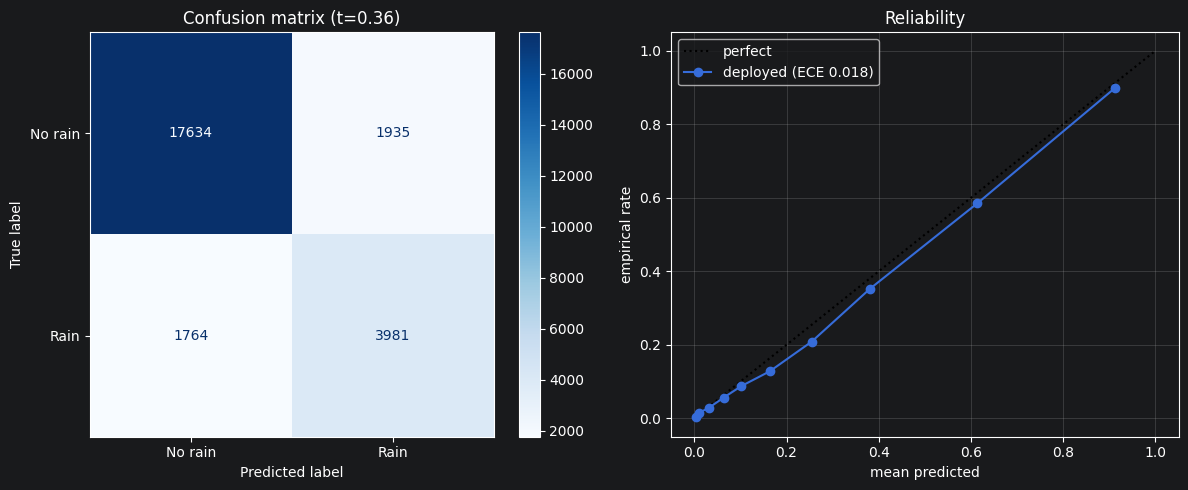

In [9]:
log_section('6. Final evaluation (chronological test)')
pr, rc, _ = precision_recall_curve(y_test, p_test)
METRICS = dict(
    threshold=THRESHOLD,
    F1=round(f1_score(y_test, y_pred), 4), precision=round(precision_score(y_test, y_pred), 4),
    recall=round(recall_score(y_test, y_pred), 4), ROC_AUC=round(roc_auc_score(y_test, p_test), 4),
    PR_AUC=round(auc(rc, pr), 4), Brier=round(brier_score_loss(y_test, p_test), 4),
    ECE=round(ece(y_test.values, p_test), 4), mean_pred=round(float(p_test.mean()), 4),
    base_rate=round(float(y_test.mean()), 4))
print('Classification report (calibrated, t = %.2f):' % THRESHOLD)
print(classification_report(y_test, y_pred))
print('Deployment metrics:')
for k, v in METRICS.items(): print(f'  {k:11s} {v}')

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['No rain','Rain']).plot(cmap='Blues', ax=ax[0])
ax[0].set_title(f'Confusion matrix (t={THRESHOLD})')
ax[1].plot([0,1],[0,1],'k:',label='perfect')
pt, pp = calibration_curve(y_test, p_test, n_bins=10, strategy='quantile')
ax[1].plot(pp, pt, 'o-', label=f'deployed (ECE {METRICS["ECE"]:.3f})')
ax[1].set_xlabel('mean predicted'); ax[1].set_ylabel('empirical rate'); ax[1].set_title('Reliability'); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); save_fig('deploy_01_eval', fig); plt.show()

## 7. Save the deployment artifact

In [10]:
log_section('7. Save artifact')
ARTIFACT = {
    'name': 'rain_xgb_k5',
    'created_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
    'xgb_model': model_full,            # XGBClassifier (device=cpu), raw probabilities
    'isotonic': isotonic,               # IsotonicRegression: raw_prob -> calibrated_prob
    'threshold': THRESHOLD,             # decision threshold on the CALIBRATED scale
    'feature_order': FEATURE_ORDER,     # exact column order expected by xgb_model
    'base_features': BASE_FEATURES, 'temporal_features': TEMPORAL_FEATURES,
    'spatial_features': SPATIAL_FEATURES,
    'K_neighbours': K_NEIGHBOURS, 'neighbours': NEIGHBOURS, 'station_coords': COORDS,
    'nearest_dist': NEAREST_DIST, 'scale_pos_weight': float(SPW),
    'xgb_params': V2_PARAMS, 'train_end': str(TRAIN_END.date()),
    'metrics_test_2016plus': METRICS,
    'predict_recipe': 'p_cal = isotonic.predict(xgb_model.predict_proba(X[feature_order])[:,1]); rain = p_cal >= threshold',
    'pipeline_inputs': ['weatherAUS_trend_grouped.csv', 'weatherAUS_MICE_cyclic.csv',
                        'weatherAUS_X_train.csv', 'weatherAUS_y_train.csv',
                        'weatherAUS_X_test.csv', 'weatherAUS_y_test.csv'],
    'notes': 'Same-station model: spatial features require recent neighbour observations at inference. '
             'For unseen stations, drop spatial_features and retrain base+temporal.',
}
ART_PATH = f'{MODEL_DIR}/rain_xgb_k5_deploy.joblib'
joblib.dump(ARTIFACT, ART_PATH)
print(f'Saved {ART_PATH} ({os.path.getsize(ART_PATH)/1e6:.1f} MB)')

META_PATH = f'{MODEL_DIR}/rain_xgb_k5_metadata.json'
with open(META_PATH, 'w', encoding='utf-8') as f:
    json.dump({k: ARTIFACT[k] for k in
               ['name','created_utc','threshold','feature_order','K_neighbours',
                'scale_pos_weight','xgb_params','train_end','metrics_test_2016plus',
                'predict_recipe','notes']}, f, indent=2)
print(f'Saved {META_PATH}')

## 8. Inference demo — reload the artifact and predict

In [11]:
log_section('8. Inference demo')
art = joblib.load(ART_PATH)
def deploy_predict(art, X):
    raw = art['xgb_model'].predict_proba(X[art['feature_order']])[:, 1]
    p_cal = art['isotonic'].predict(raw)
    return p_cal, (p_cal >= art['threshold']).astype(int)

sample = X_test.head(8)
p_cal, decision = deploy_predict(art, sample)
demo = pd.DataFrame({'calibrated_p_rain': np.round(p_cal, 3), 'predicted_rain': decision,
                     'actual_rain': y_test.head(8).values})
print(demo.to_string(index=False))
# round-trip check: reloaded artifact reproduces the test metrics
p_all, pred_all = deploy_predict(art, X_test)
print(f'\nReload round-trip F1: {f1_score(y_test, pred_all):.4f} (matches {METRICS["F1"]})')

## 9. Finalization

In [12]:
log_section('Finalization')
print(f'Results file : {_PATH}')
print(f'Artifact     : {ART_PATH}')
figs = sorted(f for f in os.listdir('figures') if f.startswith('deploy_'))
for f in figs: print(f'  figures/{f}')
sys.stdout = _ORIG; _FILE.close()
ZIP = 'XGB_deploy_artifacts.zip'
with zipfile.ZipFile(ZIP, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(_PATH)
    zf.write(ART_PATH, arcname=os.path.basename(ART_PATH))
    zf.write(META_PATH, arcname=os.path.basename(META_PATH))
    for f in figs: zf.write(f'figures/{f}')
print(f'Bundled -> {ZIP}')
if IN_COLAB:
    from google.colab import files; files.download(ZIP)
print('Done.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>